# RelativeFeatures: subtraction and division with Feature-engine

RelativeFeatures creates new columns by comparing variables with one or more reference variables. This notebook demonstrates a difference and ratios using the Ames house-price data.

## Why use relative features?

A difference can represent a gap or balance. A ratio can express a proportion or rate that is more comparable across records. Division by zero is an important edge case and must have a documented policy.

In [1]:
import importlib.util,subprocess,sys
if importlib.util.find_spec('feature_engine') is None: subprocess.check_call([sys.executable,'-m','pip','install','feature-engine'])
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from feature_engine.creation import RelativeFeatures

paths=[Path('feature-engineering/imputation/houseprice.csv'),Path('../imputation/houseprice.csv'),Path('../../imputation/houseprice.csv'),Path('houseprice.csv')]
path=next((p for p in paths if p.exists()),None)
if path is None: raise FileNotFoundError('Place houseprice.csv in feature-engineering/imputation/.')
data=pd.read_csv(path,na_values=['NA'])
X=data[['GrLivArea','LotArea','TotalBsmtSF','BsmtFinSF1','BsmtUnfSF']].fillna(0)
display(X.head())

,GrLivArea,LotArea,TotalBsmtSF,BsmtFinSF1,BsmtUnfSF
0,1710,8450,856,706,150
1,1262,9600,1262,978,284
2,1786,11250,920,486,434
3,1717,9550,756,216,540
4,2198,14260,1145,655,490


## 1. Create a subtraction feature

The total basement area minus finished basement area represents unfinished basement space. RelativeFeatures names generated columns from the variables and function unless a later rename is applied.

In [2]:
subtractor=RelativeFeatures(
    variables=['TotalBsmtSF'],
    reference=['BsmtFinSF1'],
    func=['sub'],
    fill_value=0,
    missing_values='ignore',
)
X_sub=subtractor.fit_transform(X)
print('New columns:',[c for c in X_sub.columns if c not in X.columns])
display(X_sub.tail())

New columns: ['TotalBsmtSF_sub_BsmtFinSF1']


,GrLivArea,LotArea,TotalBsmtSF,BsmtFinSF1,BsmtUnfSF,TotalBsmtSF_sub_BsmtFinSF1
1455,1647,7917,953,0,953,953
1456,2073,13175,1542,790,589,752
1457,2340,9042,1152,275,877,877
1458,1078,9717,1078,49,0,1029
1459,1256,9937,1256,830,136,426


## 2. Create ratio features

The living-area-to-lot-area ratio represents land utilisation. The finished-basement ratio represents the fraction of basement area that is finished. fill_value=0 makes zero-denominator results finite; choose a different policy when zero has a different domain meaning.

In [3]:
ratio=RelativeFeatures(
    variables=['GrLivArea','BsmtFinSF1'],
    reference=['LotArea','TotalBsmtSF'],
    func=['div'],
    fill_value=0,
    missing_values='ignore',
)
X_relative=ratio.fit_transform(X_sub)
relative_columns=[c for c in X_relative.columns if c not in X.columns]
print('Created columns:',relative_columns)
display(X_relative[relative_columns].head())
assert np.isfinite(X_relative[relative_columns].to_numpy()).all()

Created columns: ['TotalBsmtSF_sub_BsmtFinSF1', 'GrLivArea_div_LotArea', 'BsmtFinSF1_div_LotArea', 'GrLivArea_div_TotalBsmtSF', 'BsmtFinSF1_div_TotalBsmtSF']


,TotalBsmtSF_sub_BsmtFinSF1,GrLivArea_div_LotArea,BsmtFinSF1_div_LotArea,GrLivArea_div_TotalBsmtSF,BsmtFinSF1_div_TotalBsmtSF
0,150,0.202367,0.083550,1.997664,0.824766
1,284,0.131458,0.101875,1.000000,0.774960
2,434,0.158756,0.043200,1.941304,0.528261
3,540,0.179791,0.022618,2.271164,0.285714
4,490,0.154137,0.045933,1.919651,0.572052


## 3. Inspect the generated distributions

Ratios can be skewed, especially when a denominator is small. Inspect quantiles before modelling and consider capping or a transformation when extreme ratios are valid but influential.

,count,mean,std,min,1%,50%,99%,max
TotalBsmtSF_sub_BsmtFinSF1,1460.0,613.7897,437.5301,0.0000,0.0000,548.5000,1814.7600,2336.0000
GrLivArea_div_LotArea,1460.0,0.1806,0.1119,0.0095,0.0453,0.1557,0.6776,0.9454
BsmtFinSF1_div_LotArea,1460.0,0.0507,0.0575,0.0000,0.0000,0.0395,0.2601,0.3607
GrLivArea_div_TotalBsmtSF,1460.0,1.4867,0.6957,0.0000,0.0000,1.1934,3.7307,8.6667
BsmtFinSF1_div_TotalBsmtSF,1460.0,0.3951,0.3457,0.0000,0.0000,0.4273,1.0000,1.0000


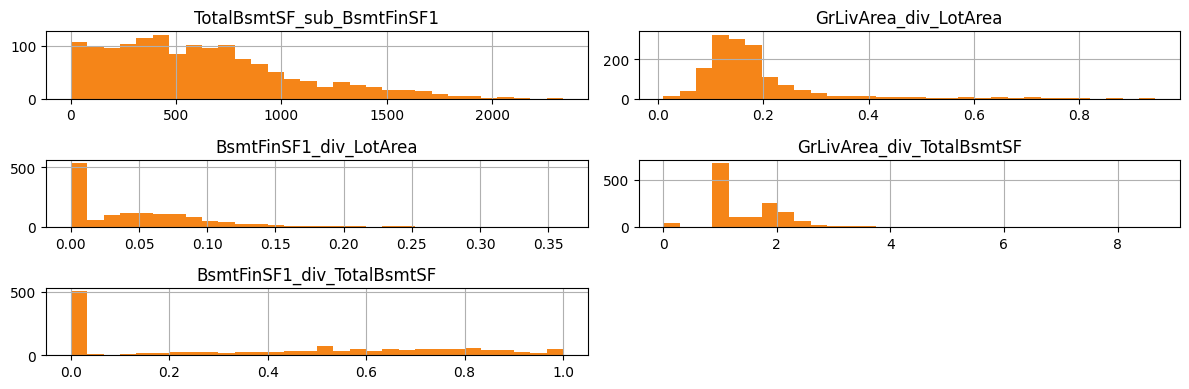

In [4]:
display(X_relative[relative_columns].describe(percentiles=[.01,.5,.99]).T.round(4))
X_relative[relative_columns].hist(bins=30,figsize=(12,4),color='#F58518'); plt.tight_layout(); plt.show()

## Summary

RelativeFeatures makes differences and ratios repeatable. Preserve the original variables when absolute size matters, protect zero denominators, and validate that every formula is available at prediction time.